In [2]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np


In [ ]:
encourage_middle2 = pd.read_csv(
    "output/encourage_middle2/similarities.csv", index_col=0
)
baseline360 = pd.read_csv("output/baseline_360/similarities.csv", index_col=0)
encourage_middle_360 = pd.read_csv(
    "output/encourage_middle_360/similarities.csv", index_col=0
)


In [ ]:
model_sims = encourage_middle_360.pivot(
    index="Rock1", columns="Rock2", values="ChatGPT Rating"
)
model_sims = model_sims.combine_first(model_sims.T)
np.fill_diagonal(model_sims.values, 9)
model_sims.to_csv(
    "output/encourage_middle_360/chatgpt_360_similarity_matrix.csv",
    index=False,
    header=False,
)

In [ ]:
shared = encourage_middle2.merge(
    encourage_middle_360, on=["Rock1", "Rock2"], suffixes=("_30", "_360")
)[["Rock1", "Rock2", "ChatGPT Rating_30", "ChatGPT Rating_360"]]
shared

,Rock1,Rock2,ChatGPT Rating_30,ChatGPT Rating_360
0,I_Andesite_06,I_Basalt_02,3.315803,3.238220
1,I_Andesite_06,I_Diorite_10,4.800473,4.767792
2,I_Andesite_06,I_Gabbro_03,5.057080,5.077581
3,I_Andesite_06,I_Granite_11,4.162969,4.251551
4,I_Andesite_06,I_Obsidian_09,1.571236,1.735955
...,...,...,...,...
430,S_Rock Gypsum_02,S_Sandstone_12,2.000087,1.934071
431,S_Rock Gypsum_02,S_Shale_04,1.831286,1.713953
432,S_Rock Salt_12,S_Sandstone_12,1.569165,1.440013
433,S_Rock Salt_12,S_Shale_04,1.700037,1.577002


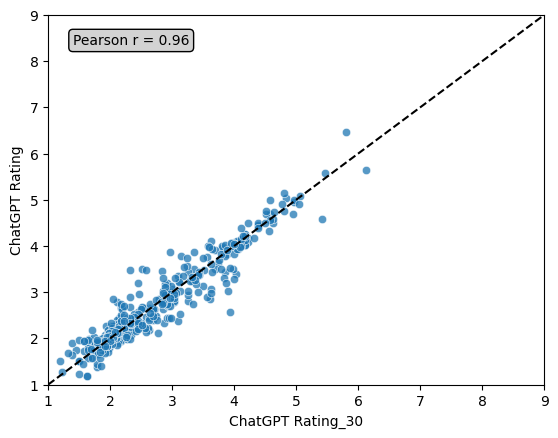

In [ ]:
sns.scatterplot(data=shared, x="ChatGPT Rating_30", y="ChatGPT Rating_360", alpha=0.75)
plt.plot([1, 9], [1, 9], "k--")
plt.xlim(1, 9)
plt.ylim(1, 9)
plt.ylabel("ChatGPT Rating")
plt.annotate(
    f"Pearson r = {shared['ChatGPT Rating_30'].corr(shared['ChatGPT Rating_360']):.2f}",
    xy=(0.05, 0.95),
    xycoords="axes fraction",
    ha="left",
    va="top",
    fontsize=10,
    bbox=dict(boxstyle="round,pad=0.3", edgecolor="black", facecolor="lightgray"),
)
plt.savefig(
    "output/encourage_middle_360/similarity_ratings_30_vs_360.pdf", bbox_inches="tight"
)

In [ ]:
baseline360.rename(
    columns={
        "ChatGPT Rating": "Baseline",
    },
    inplace=True,
)

encourage_middle_360.rename(
    columns={
        "ChatGPT Rating": "Encourage Middle",
    },
    inplace=True,
)

mrg = baseline360.merge(
    encourage_middle_360, on=["Rock1", "Rock2", "Rock1 Index", "Rock2 Index", "Human"]
)

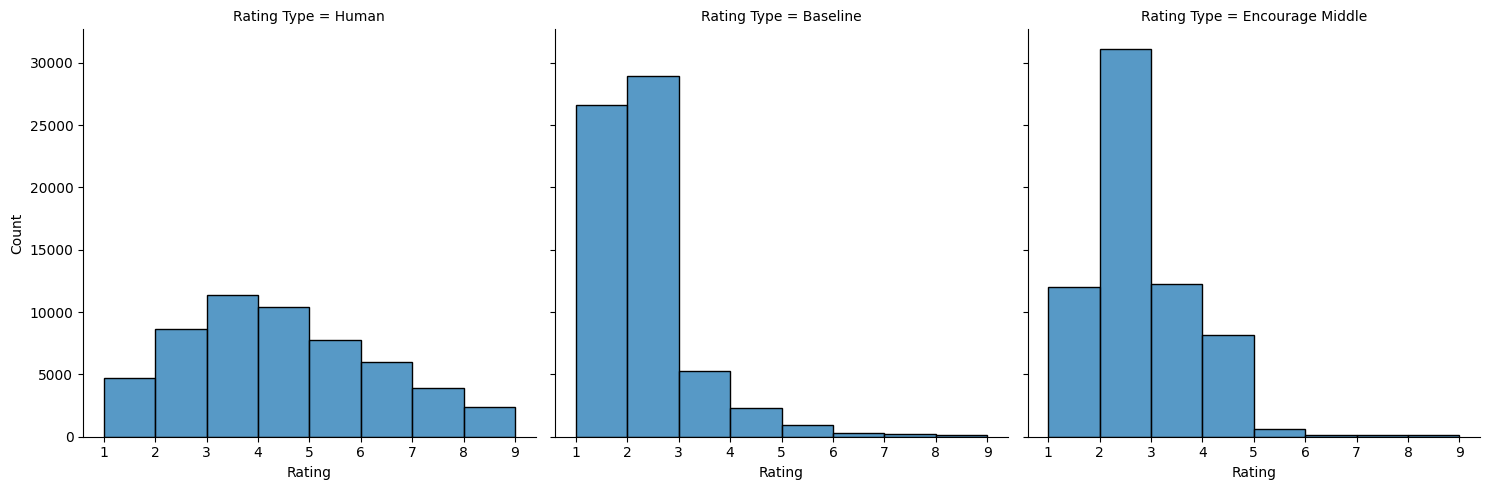

In [18]:
mlt = mrg.melt(
    id_vars=["Rock1", "Rock2"],
    value_vars=["Human", "Baseline", "Encourage Middle"],
    var_name="Rating Type",
    value_name="Rating",
)

sns.displot(
    data=mlt,
    x="Rating",
    col="Rating Type",
    kind="hist",
    bins=[1, 2, 3, 4, 5, 6, 7, 8, 9],
    facet_kws={"sharey": True, "sharex": True},
)

Text(0.05, 0.95, 'Pearson r = 0.45')

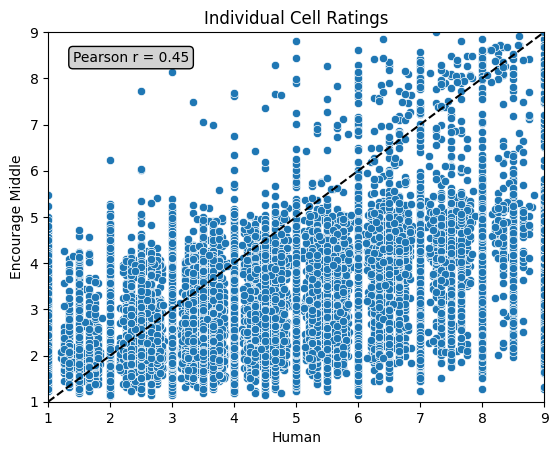

In [21]:
sns.scatterplot(
    data=encourage_middle_360,
    x="Human",
    y="Encourage Middle",
)
plt.plot([1, 9], [1, 9], "k--")
plt.xlim(1, 9)
plt.ylim(1, 9)
plt.ylabel("Encourage Middle")
plt.title("Individual Cell Ratings")
plt.annotate(
    f"Pearson r = {encourage_middle_360['Encourage Middle'].corr(baseline360['Human']):.2f}",
    xy=(0.05, 0.95),
    xycoords="axes fraction",
    ha="left",
    va="top",
    fontsize=10,
    bbox=dict(boxstyle="round,pad=0.3", edgecolor="black", facecolor="lightgray"),
)

In [ ]:
encourage_middle_360["Rock1 Category"] = (
    encourage_middle_360["Rock1"].str.split("_").str[1]
)
encourage_middle_360["Rock2 Category"] = (
    encourage_middle_360["Rock2"].str.split("_").str[1]
)
encourage_middle_360["Comparison"] = (
    encourage_middle_360["Rock1 Category"]
    + " vs "
    + encourage_middle_360["Rock2 Category"]
)
comparison = (
    encourage_middle_360.groupby("Comparison")[["Human", "Encourage Middle"]]
    .mean()
    .reset_index()
)

Text(0.05, 0.95, 'Pearson r = 0.89')

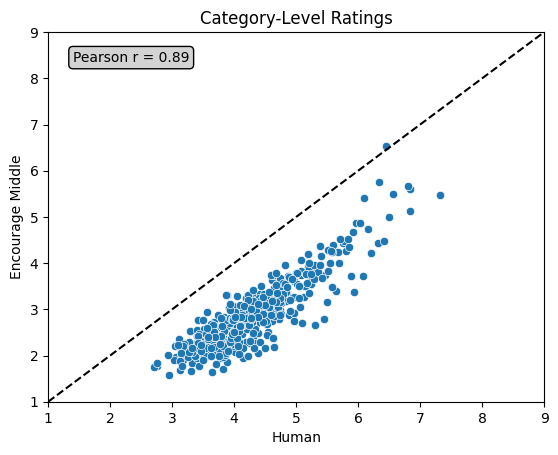

In [25]:
sns.scatterplot(
    data=comparison,
    x="Human",
    y="Encourage Middle",
)
plt.plot([1, 9], [1, 9], "k--")
plt.xlim(1, 9)
plt.ylim(1, 9)
plt.ylabel("Encourage Middle")
plt.title("Category-Level Ratings")
plt.annotate(
    f"Pearson r = {comparison['Encourage Middle'].corr(comparison['Human']):.2f}",
    xy=(0.05, 0.95),
    xycoords="axes fraction",
    ha="left",
    va="top",
    fontsize=10,
    bbox=dict(boxstyle="round,pad=0.3", edgecolor="black", facecolor="lightgray"),
)

In [29]:
baseline360

,Rock1,Rock2,Rock1 Index,Rock2 Index,Human,Baseline
index,,,,,,
0,I_Andesite_01,I_Andesite_02,0,1,4.8333,4.418295
1,I_Andesite_01,I_Andesite_03,0,2,5.4000,4.520330
2,I_Andesite_01,I_Andesite_04,0,3,5.7500,3.616274
3,I_Andesite_01,I_Andesite_05,0,4,6.5000,3.005547
4,I_Andesite_01,I_Andesite_06,0,5,4.5000,4.183161
...,...,...,...,...,...,...
64615,S_Shale_09,S_Shale_11,356,358,4.6000,2.778230
64616,S_Shale_09,S_Shale_12,356,359,3.6000,4.070163
64617,S_Shale_10,S_Shale_11,357,358,1.0000,1.664725


In [ ]:
import numpy as np

np.corrcoef(encourage_middle_360["Encourage Middle"], baseline360["Baseline"])


array([[1.        , 0.92264455],
       [0.92264455, 1.        ]])

In [ ]:
from scipy.stats import spearmanr

spearmanr(encourage_middle_360["Encourage Middle"], baseline360["Baseline"])

SignificanceResult(statistic=np.float64(0.9325749908240455), pvalue=np.float64(0.0))

Text(0, 0.5, 'Encourage Middle')

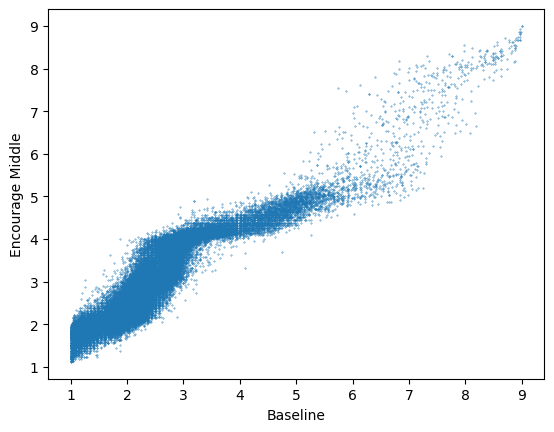

In [ ]:
plt.scatter(baseline360["Baseline"], encourage_middle_360["Encourage Middle"], s=0.1)
plt.xlabel("Baseline")
plt.ylabel("Encourage Middle")